Aim: Evaluate if the spectra shape of the peak are the same for at each service.

# Do peaks of the same service have the same spectral shape?

Goal: for each service (frequency allocation), overlay every peak detected in the scans
`scan_000_P1_ND0`, `scan_001_P0_ND0` and `scan_001_P1_ND0`, and test whether their spectral shapes agree.

Steps:

1. Load the three scans and average each one in time.
2. Detrend and detect high- and low-level peaks with `rfi_pipeline`.
3. Assign each peak to a service, using the same allocation table as `peak_analyses_t6.ipynb`.
4. Cut out each peak, centre it on `fc` and normalise it to its peak power.
5. Overlay the peaks per service in two ways: (a) against frequency offset in kHz, which keeps the width; (b) against offset in units of the peak's own spectral width, which isolates the shape.
6. Quantify the agreement: correlation of each peak with its service's median template, and shape descriptors.
7. Compare scans within each service: correlation between per-scan templates and a Kruskal–Wallis test on the shape descriptors.
8. Summarise the result per service.

In [1]:
import os
import warnings
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kruskal

from rfi_pipeline import analyze_time_bins, detrend_spectrum

import scienceplots
plt.style.use(['science', 'no-latex'])

# np.nanmedian warns on grid points no profile reaches; those stay NaN on purpose
warnings.filterwarnings('ignore', message='All-NaN slice encountered')

## 1. Load the data

Same slicing as `peak_analyses_t6.ipynb`: drop the first 30 spectra and the band edges (`1600:-60`). Frequencies are in **kHz**.

In [2]:
filename = "EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5"
path = f'/home/chavango/Master/DATA/SKAMPI_data/{filename}'
dirname = filename.split('.')[0]
out_dir = os.path.join(dirname, 'shape_by_service')

to_save = False  # Set to True to save the plots and tables

SCANS = ["scan/000/P1_ND0", "scan/001/P0_ND0", "scan/001/P1_ND0"]
SIGMA_VALUES = {"high": 3, "low": 5}

SCAN_TYPES = {'000': 'Azimuth-Scan', '001': 'Elevation-Scan'}
POLARIZATIONS = {'P0': 'Horizontal', 'P1': 'Vertical'}

def scan_label(scan):
    scan_id, pol_nd = scan.split('/')[1:]
    return f"{SCAN_TYPES[scan_id]} | {POLARIZATIONS[pol_nd.split('_')[0]]} pol."

spectra = {}
with h5py.File(path, 'r') as f:
    for g in SCANS:
        spectra[g] = f[f"{g}/spectrum"][30:, 1600:-60]
        frequency_khz = f[f"{g}/frequency"][1600:-60] / 1e3  # kHz, same axis for every scan

channel_spacing = np.median(np.diff(frequency_khz))
for g, s in spectra.items():
    print(f"{g.replace('/', '_')}: {s.shape}  ({scan_label(g)})")
print(f"channel spacing = {channel_spacing:.2f} kHz")

scan_000_P1_ND0: (634, 63877)  (Azimuth-Scan | Vertical pol.)
scan_001_P0_ND0: (636, 63877)  (Elevation-Scan | Horizontal pol.)
scan_001_P1_ND0: (636, 63877)  (Elevation-Scan | Vertical pol.)
channel spacing = 26.70 kHz


## 2. Time-average, detrend and detect peaks

Each scan is averaged in time. The averaged spectrum is detrended (ASLS) and searched for high-level (3σ) and then low-level (5σ) peaks.

When two local maxima share the same feature edges (`start_index`, `end_index`), they get the same `fc` and the same cut-out. Only the strongest one is kept, so a feature is not overlaid twice.

In [3]:
peak_tables, detrended = [], {}
for scan in SCANS:
    mean_spec = spectra[scan].mean(axis=0, keepdims=True)
    res = analyze_time_bins(mean_spec, frequency_khz, time_bins=[0],
                            rf_level="both", sigma_values=SIGMA_VALUES)
    res = (res.sort_values('peak_height', ascending=False)
              .drop_duplicates(['start_index', 'end_index'])
              .sort_values('f_peak'))
    res.insert(0, 'scan', scan.replace('/', '_'))
    res.insert(1, 'scan_label', scan_label(scan))
    peak_tables.append(res)
    detrended[scan.replace('/', '_')], _ = detrend_spectrum(mean_spec[0], frequency_khz)

peaks = pd.concat(peak_tables, ignore_index=True)
peaks.groupby(['scan', 'detection_level']).size().unstack(fill_value=0)

detection_level,high,low
scan,,
scan_000_P1_ND0,4,9
scan_001_P0_ND0,5,14
scan_001_P1_ND0,4,8


## 3. Assign each peak to a service

These are the allocations from `peak_analyses_t6.ipynb`. When allocations overlap, the peak goes to the **narrowest** one. Peaks outside every allocation are labelled `Unallocated`.

In [4]:
# Frequency allocations (GHz), as in SKAMPI_RFI_PIPELINE/rfi_analysis_workflow.ipynb
RFI_BANDS = {
    "Cellular GSM Uplink": (1.71, 1.785),
    "Cellular GSM Downlink": (1.805, 1.88),
    "DECT Phones": (1.88, 1.90),
    "UMTS Uplink": (1.92, 1.98),
    "UMTS Downlink": (2.11, 2.17),
    "Mobile Satellite": (2.00, 2.20),
    "Space Research / EESS": (2.20, 2.29),
    "IMT 2300 (4G/5G)": (2.30, 2.40),
    "Wi-Fi / Bluetooth (ISM)": (2.40, 2.483),
    "LTE / 5G (2600 band)": (2.50, 2.69),
    "Air Traffic Radar": (2.70, 2.90),
    "Weather Radar": (2.70, 3.00),
    "Microwave Backhaul": (3.00, 3.30),
    "5G NR (n78)": (3.30, 3.60),
}
TRANSITION_BANDS = {
    "Gap: GSM DL to GSM UL": (1.785, 1.805),
    "Gap: DECT to UMTS UL": (1.90, 1.92),
    "Gap: UMTS UL to MSS": (1.98, 2.00),
    "Gap: EESS to IMT-2300": (2.29, 2.30),
    "Gap: ISM to LTE 2600": (2.483, 2.50),
    "Gap: LTE 2600 to Radar": (2.69, 2.70),
}
ALL_BANDS = dict(sorted({**RFI_BANDS, **TRANSITION_BANDS}.items(), key=lambda kv: kv[1][0]))

def assign_band(f_khz):
    # Narrowest allocation containing f (so overlapping bands resolve to the most specific one)
    f_ghz = f_khz / 1e6
    hits = [(hi - lo, name) for name, (lo, hi) in ALL_BANDS.items() if lo <= f_ghz < hi]
    return min(hits)[1] if hits else 'Unallocated'

peaks['service'] = peaks['fc'].map(assign_band)
SERVICE_ORDER = [b for b in [*ALL_BANDS, 'Unallocated'] if b in set(peaks['service'])]

peaks.groupby(['service', 'scan']).size().unstack(fill_value=0).reindex(SERVICE_ORDER)

scan,scan_000_P1_ND0,scan_001_P0_ND0,scan_001_P1_ND0
service,,,
Cellular GSM Downlink,1,2,1
Mobile Satellite,5,8,4
UMTS Downlink,2,2,2
Space Research / EESS,1,2,1
IMT 2300 (4G/5G),2,1,2
Gap: ISM to LTE 2600,1,3,1
LTE / 5G (2600 band),1,1,1


## 4. Cut out and normalise each peak

For each peak, take the detrended spectrum within ±`HALF_WINDOW_B99` × B99 of `fc`, then:

* **Amplitude:** divide by the power at the peak channel, so every peak has a maximum of 1. This removes differences in received power.
* **Frequency (a):** Δf = f − fc in kHz. This keeps the bandwidth, so peaks of the same service only overlap if they also have the same width.
* **Frequency (b):** x = (f − fc) / σ_f, where σ_f is the power-weighted spectral standard deviation (`moment_std`). This removes the width and leaves only the profile shape, such as a Gaussian, flat-top, or asymmetric profile.

Each profile is interpolated onto a common grid so peaks can be compared point by point. Points outside the cut-out are set to NaN.

In [5]:
HALF_WINDOW_B99 = 1.0                    # cut-out half-width in units of B99
X_GRID = np.linspace(-5, 5, 401)         # width-normalised grid, (f - fc) / sigma_f

def cut_out(row):
    p = detrended[row['scan']]
    half = HALF_WINDOW_B99 * row['B99'] if np.isfinite(row['B99']) and row['B99'] > 0 \
        else 10 * channel_spacing
    sel = np.abs(frequency_khz - row['fc']) <= half
    df = frequency_khz[sel] - row['fc']
    prof = p[sel] / p[int(row['peak_index'])]
    return df, prof

profiles = {}            # peak id -> (delta_f_kHz, normalised power)
for i, row in peaks.iterrows():
    profiles[i] = cut_out(row)

def on_grid(df, prof, grid):
    return np.interp(grid, df, prof, left=np.nan, right=np.nan)

# width-normalised profiles on the common grid, one row per peak
X = np.vstack([on_grid(profiles[i][0] / peaks.at[i, 'moment_std'], profiles[i][1], X_GRID)
               for i in peaks.index])
print(f"{len(peaks)} peaks, width-normalised profile matrix: {X.shape}")

44 peaks, width-normalised profile matrix: (44, 401)


## 5. Overlay the peaks per service

One panel per service, colour = scan, solid = high level, dashed = low level. The thick black line is the service's **median template**.

In [6]:
SCAN_COLOURS = {s.replace('/', '_'): c for s, c in zip(SCANS, ['C0', 'C1', 'C2'])}
LEVEL_STYLES = {'high': '-', 'low': '--'}

def service_axes(n, ncols=3, size=(4.2, 3.0)):
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size[0] * ncols, size[1] * nrows), squeeze=False)
    for ax in axes.flat[n:]:
        ax.set_visible(False)
    return fig, axes.flat

def add_scan_legend(fig):
    handles = [plt.Line2D([], [], color=c, label=s) for s, c in SCAN_COLOURS.items()]
    handles += [plt.Line2D([], [], color='k', ls=ls, label=f'{lvl} level') for lvl, ls in LEVEL_STYLES.items()]
    handles += [plt.Line2D([], [], color='k', lw=2.5, alpha=0.45, label='median template')]
    fig.legend(handles=handles, loc='lower center', ncol=len(handles), frameon=False,
               bbox_to_anchor=(0.5, -0.02))

### 5a. Frequency offset in kHz (shape + width)

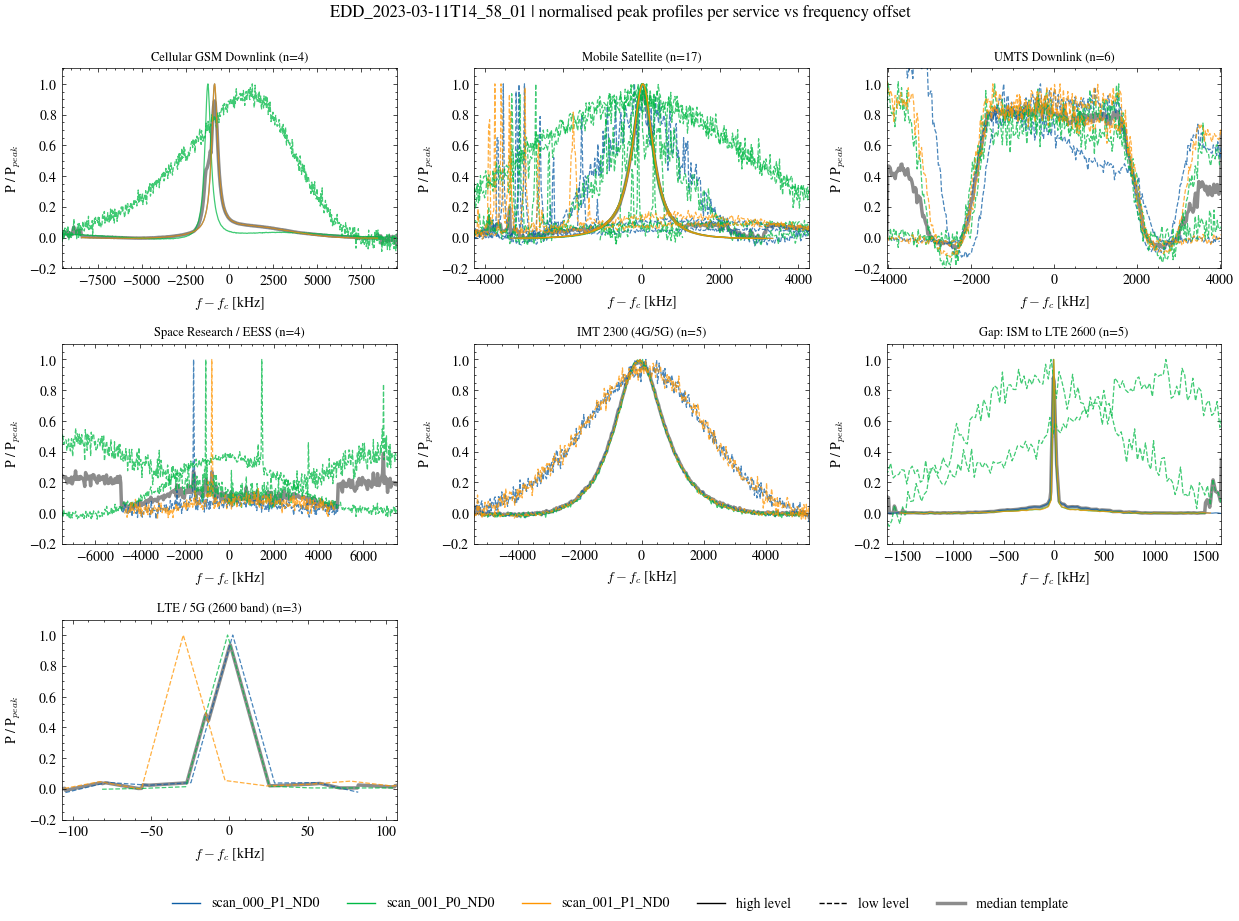

In [7]:
fig, axes = service_axes(len(SERVICE_ORDER))
for ax, service in zip(axes, SERVICE_ORDER):
    d = peaks[peaks['service'] == service]
    half = HALF_WINDOW_B99 * d['B99'].median()
    grid_khz = np.linspace(-half, half, 401)
    stack = []
    for i, row in d.iterrows():
        df, prof = profiles[i]
        ax.plot(df, prof, color=SCAN_COLOURS[row['scan']], ls=LEVEL_STYLES[row['detection_level']],
                lw=0.9, alpha=0.75)
        stack.append(on_grid(df, prof, grid_khz))
    if len(stack) > 1:
        ax.plot(grid_khz, np.nanmedian(stack, axis=0), color='k', lw=2.5, alpha=0.45, zorder=1)
    ax.set_xlim(-half, half)
    ax.set_ylim(-0.2, 1.1)
    ax.set_title(f"{service} (n={len(d)})", fontsize=9)
    ax.set_xlabel(r'$f - f_c$ [kHz]')
    ax.set_ylabel('P / P$_{peak}$')
add_scan_legend(fig)
fig.suptitle(f'{dirname} | normalised peak profiles per service vs frequency offset', y=1.0)
fig.tight_layout(rect=(0, 0.03, 1, 1))

if to_save:
    os.makedirs(out_dir, exist_ok=True)
    fig.savefig(f'{out_dir}/peak_overlay_kHz_by_service.pdf', bbox_inches='tight')
    fig.savefig(f'{out_dir}/peak_overlay_kHz_by_service.png', bbox_inches='tight')
plt.show()

### 5b. Width-normalised offset (shape only)

If the curves of a service collapse onto the template here but not in 5a, the peaks share a shape and differ only in bandwidth.

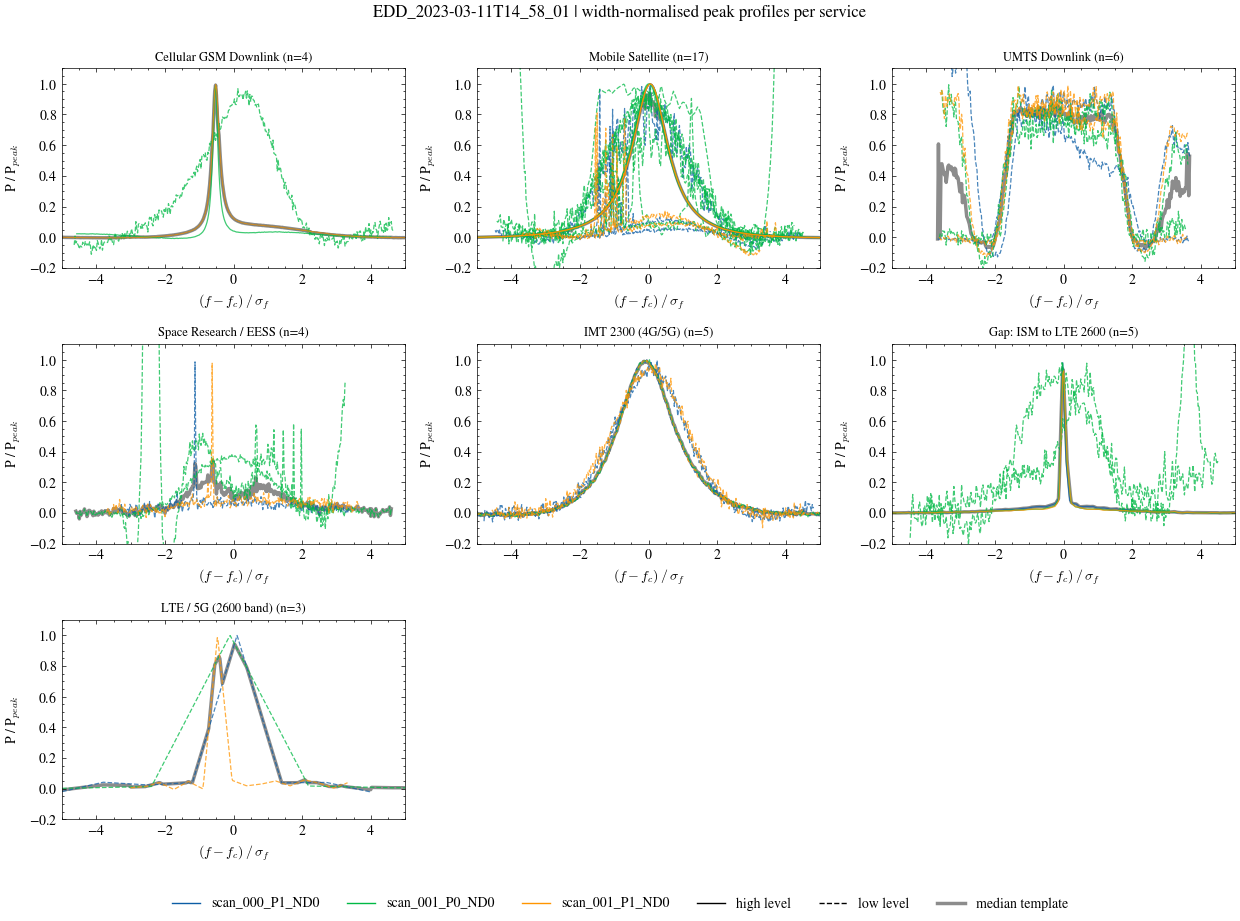

In [8]:
fig, axes = service_axes(len(SERVICE_ORDER))
for ax, service in zip(axes, SERVICE_ORDER):
    idx = peaks.index[peaks['service'] == service]
    for i in idx:
        row = peaks.loc[i]
        ax.plot(X_GRID, X[peaks.index.get_loc(i)], color=SCAN_COLOURS[row['scan']],
                ls=LEVEL_STYLES[row['detection_level']], lw=0.9, alpha=0.75)
    if len(idx) > 1:
        ax.plot(X_GRID, np.nanmedian(X[peaks.index.get_indexer(idx)], axis=0), color='k', lw=2.5,
                alpha=0.45, zorder=1)
    ax.set_xlim(X_GRID[0], X_GRID[-1])
    ax.set_ylim(-0.2, 1.1)
    ax.set_title(f"{service} (n={len(idx)})", fontsize=9)
    ax.set_xlabel(r'$(f - f_c)\,/\,\sigma_f$')
    ax.set_ylabel('P / P$_{peak}$')
add_scan_legend(fig)
fig.suptitle(f'{dirname} | width-normalised peak profiles per service', y=1.0)
fig.tight_layout(rect=(0, 0.03, 1, 1))

if to_save:
    fig.savefig(f'{out_dir}/peak_overlay_normalised_by_service.pdf', bbox_inches='tight')
    fig.savefig(f'{out_dir}/peak_overlay_normalised_by_service.png', bbox_inches='tight')
plt.show()

## 6. Quantify the shape agreement within each service

**6a. Profile correlation.** Each peak is compared with a leave-one-out median template of its service, built from the other peaks. The template excludes the peak itself so a peak cannot match itself. This uses the width-normalised profiles from 5b, over the points where both curves are defined.

* `r`: Pearson correlation with the template. Values near 1 mean the same shape.
* `nrms`: RMS of the residual between the peak and the template, in units of the normalised peak power.

**6b. Shape descriptors** (dimensionless, so they do not depend on power or width):

* `B10/FWHM`, `B20/FWHM`, `B99/FWHM`: how fast the skirts fall off relative to the core. For a Gaussian these are 1.82, 2.57 and 2.19. B99/FWHM is the pipeline's `RBW` (no unit), as in `peak_analyses_t6.ipynb`.
* `S`: power-weighted skewness (asymmetry).
* `FWHM/Δch`: the FWHM in channels. Below about 2 channels, the shape is not resolved and the ratios above mostly reflect channel quantisation.

In [9]:
def masked_corr(a, b):
    ok = np.isfinite(a) & np.isfinite(b)
    if ok.sum() < 10:
        return np.nan, np.nan
    r = np.corrcoef(a[ok], b[ok])[0, 1]
    nrms = np.sqrt(np.mean((a[ok] - b[ok]) ** 2))
    return r, nrms

r_vals, nrms_vals = np.full(len(peaks), np.nan), np.full(len(peaks), np.nan)
for service in SERVICE_ORDER:
    pos = np.flatnonzero(peaks['service'].values == service)
    if len(pos) < 2:
        continue
    for k in pos:
        template = np.nanmedian(X[pos[pos != k]], axis=0)
        r_vals[k], nrms_vals[k] = masked_corr(X[k], template)

peaks['r_template'] = r_vals
peaks['nrms_template'] = nrms_vals
peaks['B10/FWHM'] = peaks['B10'] / peaks['FWHM']
peaks['B20/FWHM'] = peaks['B20'] / peaks['FWHM']
peaks['B99/FWHM'] = peaks['RBW']   # RBW = B99 / FWHM from the pipeline
peaks['FWHM/dch'] = peaks['FWHM'] / channel_spacing
peaks['resolved'] = peaks['FWHM/dch'] >= 2

SHAPE_METRICS = ['B10/FWHM', 'B20/FWHM', 'B99/FWHM', 'S']
GAUSSIAN = {'B10/FWHM': np.sqrt(10 / 3.0103), 'B20/FWHM': np.sqrt(20 / 3.0103), 'B99/FWHM': 2 * 2.576 / 2.355}

peaks[['scan', 'service', 'detection_level', 'fc', 'FWHM', 'B99', 'r_template', 'nrms_template',
       *SHAPE_METRICS, 'FWHM/dch', 'resolved']].sort_values(['service', 'scan'])

,scan,service,detection_level,fc,B3,B99,r_template,nrms_template,B10/B3,B20/B3,B99/B3,S,B3/dch,resolved
0,scan_000_P1_ND0,Cellular GSM Downlink,high,1.820476e+06,433.252060,8438.110352,0.996053,0.013935,4.096423,19.551745,19.476215,1.306587,16.224918,True
13,scan_001_P0_ND0,Cellular GSM Downlink,high,1.820852e+06,410.554682,10601.043701,0.958656,0.051254,2.958516,22.439415,25.821271,1.793043,15.374921,True
14,scan_001_P0_ND0,Cellular GSM Downlink,low,1.846689e+06,6238.658081,14499.664307,0.506708,0.329979,1.987723,2.484747,2.324164,-0.377406,233.632398,True
32,scan_001_P1_ND0,Cellular GSM Downlink,high,1.820469e+06,433.397048,8438.110352,0.995986,0.014457,4.136541,19.555824,19.469700,1.306754,16.230348,True
11,scan_000_P1_ND0,Gap: ISM to LTE 2600,high,2.492014e+06,35.069997,1655.578613,0.753398,0.113646,2.248766,37.723036,47.207835,-0.029971,1.313341,False
28,scan_001_P0_ND0,Gap: ISM to LTE 2600,low,2.486041e+06,1704.484166,6649.017334,0.009486,1.679587,3.066059,4.080738,3.900897,-0.776264,63.831471,True
29,scan_001_P0_ND0,Gap: ISM to LTE 2600,high,2.492011e+06,34.397081,1495.361328,0.721925,0.118279,2.219896,31.651003,43.473495,-0.093275,1.288141,False
30,scan_001_P0_ND0,Gap: ISM to LTE 2600,low,2.497084e+06,1523.161419,3177.642822,0.438030,0.378497,1.767948,2.217739,2.086215,0.377540,57.041090,True
42,scan_001_P1_ND0,Gap: ISM to LTE 2600,high,2.492009e+06,34.376640,1548.767090,0.724986,0.119485,2.217456,31.781735,45.052894,-0.241802,1.287376,False
9,scan_000_P1_ND0,IMT 2300 (4G/5G),low,2.362949e+06,1837.989999,5393.981934,0.995099,0.033738,2.205699,3.325772,2.934718,0.261590,68.831150,True


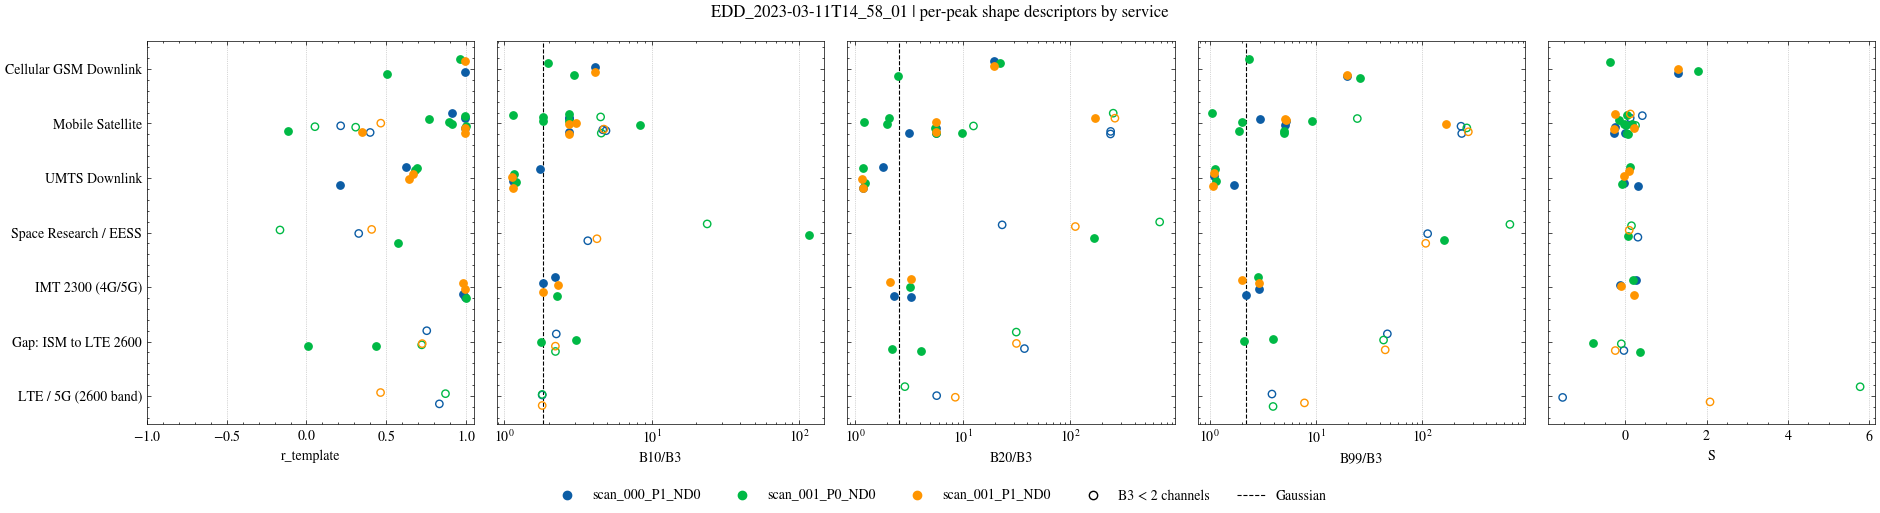

In [10]:
# shape descriptors per service: one point per peak, colour = scan, hollow = unresolved (FWHM < 2 channels)
fig, axes = plt.subplots(1, len(SHAPE_METRICS) + 1, figsize=(19, 5), sharey=True)
ypos = {s: k for k, s in enumerate(SERVICE_ORDER)}
rng = np.random.default_rng(0)
for ax, metric in zip(axes, ['r_template', *SHAPE_METRICS]):
    for _, row in peaks.iterrows():
        y = ypos[row['service']] + rng.uniform(-0.2, 0.2)
        c = SCAN_COLOURS[row['scan']]
        ax.scatter(row[metric], y, s=28, edgecolors=c,
                   facecolors=c if row['resolved'] else 'none', zorder=3)
    if metric in GAUSSIAN:
        ax.axvline(GAUSSIAN[metric], color='k', ls='--', lw=0.8, label='Gaussian')
    if metric in {'B10/FWHM', 'B20/FWHM', 'B99/FWHM'}:
        ax.set_xscale('log')
    ax.set_xlabel(metric)
    ax.grid(True, axis='x', ls=':', lw=0.5)
axes[0].set_yticks(range(len(SERVICE_ORDER)))
axes[0].set_yticklabels(SERVICE_ORDER)
axes[0].invert_yaxis()
axes[0].set_xlim(-1, 1.05)
handles = [plt.Line2D([], [], marker='o', ls='', color=c, label=s) for s, c in SCAN_COLOURS.items()]
handles += [plt.Line2D([], [], marker='o', ls='', mfc='none', mec='k', label='FWHM < 2 channels'),
            plt.Line2D([], [], color='k', ls='--', lw=0.8, label='Gaussian')]
fig.legend(handles=handles, loc='lower center', ncol=len(handles), frameon=False, bbox_to_anchor=(0.5, -0.04))
fig.suptitle(f'{dirname} | per-peak shape descriptors by service')
fig.tight_layout(rect=(0, 0.03, 1, 1))

if to_save:
    fig.savefig(f'{out_dir}/shape_descriptors_by_service.pdf', bbox_inches='tight')
    fig.savefig(f'{out_dir}/shape_descriptors_by_service.png', bbox_inches='tight')
plt.show()

## 7. Compare the scans within each service

Does the same service look the same in every scan (azimuth vs elevation scan, H vs V polarisation)?

* **Template correlation between scans:** build one median width-normalised template per (service, scan) and correlate the templates of each scan pair.
* **Kruskal–Wallis test** on each shape descriptor, with the scans as groups. A small p-value means at least one scan's distribution differs. It is only computed for services where at least two scans have `MIN_PEAKS_TEST` or more peaks. With this few peaks, treat the result as indicative.

In [11]:
from itertools import combinations

scan_names = list(SCAN_COLOURS)
pair_rows = []
for service in SERVICE_ORDER:
    templates = {}
    for s in scan_names:
        pos = np.flatnonzero((peaks['service'].values == service) & (peaks['scan'].values == s))
        if len(pos):
            templates[s] = np.nanmedian(X[pos], axis=0)
    for a, b in combinations(scan_names, 2):
        if a in templates and b in templates:
            r, nrms = masked_corr(templates[a], templates[b])
            pair_rows.append({'service': service, 'scan_a': a, 'scan_b': b, 'r': r, 'nrms': nrms})

scan_pairs = pd.DataFrame(pair_rows)
scan_pairs.pivot_table(index='service', columns=['scan_a', 'scan_b'], values='r').reindex(
    [s for s in SERVICE_ORDER if s in set(scan_pairs['service'])]).round(3)

scan_a                scan_000_P1_ND0                 scan_001_P0_ND0
scan_b                scan_001_P0_ND0 scan_001_P1_ND0 scan_001_P1_ND0
service                                                              
Cellular GSM Downlink           0.734           1.000           0.734
Mobile Satellite                0.980           0.983           0.984
UMTS Downlink                   0.926           0.938           0.988
Space Research / EESS          -0.059           0.093          -0.075
IMT 2300 (4G/5G)                0.995           0.998           0.994
Gap: ISM to LTE 2600            0.517           0.982           0.489
LTE / 5G (2600 band)            0.890           0.404           0.492

In [12]:
MIN_PEAKS_TEST = 2

rows = []
for service in SERVICE_ORDER:
    d = peaks[peaks['service'] == service]
    for metric in ['r_template', *SHAPE_METRICS]:
        groups_ = [g[metric].dropna() for _, g in d.groupby('scan')]
        groups_ = [g for g in groups_ if len(g) >= MIN_PEAKS_TEST]
        if len(groups_) >= 2 and np.ptp(np.concatenate(groups_)) > 0:
            H, p = kruskal(*groups_)
            rows.append({'service': service, 'metric': metric, 'n_scans': len(groups_), 'H': H, 'p_value': p})

scan_test = pd.DataFrame(rows, columns=['service', 'metric', 'n_scans', 'H', 'p_value'])
scan_test

,service,metric,n_scans,H,p_value
0,Mobile Satellite,r_template,3,0.235294,0.889010
1,Mobile Satellite,B10/B3,3,1.134314,0.567136
2,Mobile Satellite,B20/B3,3,2.637255,0.267502
3,Mobile Satellite,B99/B3,3,2.792157,0.247566
4,Mobile Satellite,S,3,0.475490,0.788404
5,UMTS Downlink,r_template,3,4.571429,0.101701
6,UMTS Downlink,B10/B3,3,3.428571,0.180092
7,UMTS Downlink,B20/B3,3,2.571429,0.276453
8,UMTS Downlink,B99/B3,3,2.000000,0.367879
9,UMTS Downlink,S,3,0.285714,0.866878


## 8. Summary per service

Rule of thumb for "same shape":

* median leave-one-out `r` ≥ `R_SAME`, **and**
* at least `FRAC_SAME` of the peaks have `r` ≥ `R_SAME`, **and**
* the spread of the shape descriptors is small: the coefficient of variation (CV) of `B20/FWHM` is below `CV_SAME`.

A service with a single peak cannot be tested. A service whose peaks are mostly unresolved (FWHM < 2 channels) is flagged, because its shape is set by the channel response rather than the emission. Adjust the thresholds as needed.

In [13]:
R_SAME, FRAC_SAME, CV_SAME = 0.9, 0.75, 0.3

def cv(x):
    x = x.dropna()
    return x.std() / abs(x.mean()) if len(x) > 1 and x.mean() != 0 else np.nan

summary = (peaks.groupby('service')
           .agg(n_peaks=('fc', 'size'),
                n_scans=('scan', 'nunique'),
                frac_resolved=('resolved', 'mean'),
                r_median=('r_template', 'median'),
                r_min=('r_template', 'min'),
                frac_r_ok=('r_template', lambda r: (r >= R_SAME).mean() if r.notna().any() else np.nan),
                nrms_median=('nrms_template', 'median'),
                B20_FWHM_median=('B20/FWHM', 'median'),
                B20_FWHM_cv=('B20/FWHM', cv),
                B99_FWHM_median=('B99/FWHM', 'median'),
                S_median=('S', 'median'))
           .reindex(SERVICE_ORDER))

def verdict(row):
    if row['n_peaks'] < 2:
        return 'single peak - not testable'
    same = (row['r_median'] >= R_SAME and row['frac_r_ok'] >= FRAC_SAME
            and (np.isnan(row['B20_FWHM_cv']) or row['B20_FWHM_cv'] < CV_SAME))
    note = '' if row['frac_resolved'] >= 0.5 else ' (mostly unresolved)'
    return ('same shape' if same else 'different shapes') + note

summary['verdict'] = summary.apply(verdict, axis=1)
summary.round(3)

,n_peaks,n_scans,frac_resolved,r_median,r_min,frac_r_ok,nrms_median,B20_B3_median,B20_B3_cv,B99_B3_median,S_median,verdict
service,,,,,,,,,,,,
Cellular GSM Downlink,4,3,1.000,0.977,0.507,0.750,0.033,19.554,0.570,19.473,1.307,different shapes
Mobile Satellite,17,3,0.706,0.892,-0.116,0.471,0.173,5.691,1.499,5.175,0.034,different shapes
UMTS Downlink,6,3,1.000,0.655,0.211,0.000,0.323,1.193,0.193,1.110,0.030,different shapes
Space Research / EESS,4,3,0.250,0.368,-0.166,0.000,0.130,139.799,1.207,137.500,0.128,different shapes (mostly unresolved)
IMT 2300 (4G/5G),5,3,1.000,0.995,0.979,1.000,0.034,3.275,0.211,2.863,0.186,same shape
Gap: ISM to LTE 2600,5,3,0.400,0.722,0.009,0.000,0.119,31.651,0.788,43.473,-0.093,different shapes (mostly unresolved)
LTE / 5G (2600 band),3,3,0.000,0.832,0.464,0.000,0.233,5.744,0.493,3.948,2.085,different shapes (mostly unresolved)


In [14]:
if to_save:
    os.makedirs(out_dir, exist_ok=True)
    peaks.drop(columns=['time_bin']).to_csv(f'{out_dir}/peak_shapes_per_peak.csv', index=False)
    summary.to_csv(f'{out_dir}/peak_shapes_summary_by_service.csv')
    scan_pairs.to_csv(f'{out_dir}/peak_shapes_scan_pairs.csv', index=False)
    scan_test.to_csv(f'{out_dir}/peak_shapes_scan_test.csv', index=False)
    print(f"Saved tables to {out_dir}/")